# 02 – Modelling and evaluation

Forecast East-region PM2.5 for the next 1–6 hours, compare models against
baselines, and look at where the best model fails.

**How to reproduce:** the heavy lifting lives in `src/`. Either run
`python -m src.train` once from the project folder (≈ 2–15 min depending on
the machine) and then run this notebook, or set `RUN_TRAINING = True` below.
Figures 07–13 in `reports/figures/` come from `python -m src.evaluate`, which
the last cell of section 3 also calls.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json

import pandas as pd
from IPython.display import Image, display

from src import evaluate, train
from src.data import load_clean
from src.predict import forecast

RUN_TRAINING = False  # set to True to retrain everything from scratch
if RUN_TRAINING or not (train.RESULTS_DIR / "summary.json").exists():
    train.run()

FIGURES = ROOT / "reports" / "figures"
pd.set_option("display.precision", 3)

## 1. Setup recap

* **Input:** forecast origin *t*; 49 features from data up to *t* (last 24 h
  of East, last 3 h of the other regions, rolling statistics, calendar).
* **Output:** East PM2.5 at *t*+1 … *t*+6.
* **Split by time** with a 6-hour gap: train 2014-04 → 2022, validation
  2023, test 2024 → 2026-09.
* **Selection:** hyper-parameters and the final model are chosen on the
  validation year only; the test period is scored once at the end.

In [2]:
summary = json.loads((train.RESULTS_DIR / "summary.json").read_text())
print("Best model:", summary["best_model"])
print("Settings:  ", summary["best_params"])

Best model: hist_gradient_boosting
Settings:   {'l2_regularization': 1.0, 'learning_rate': 0.1, 'log_target': False, 'max_iter': 300, 'max_leaf_nodes': 15}


## 2. Hyper-parameter tuning (validation year 2023)

In [3]:
tuning = pd.read_csv(train.RESULTS_DIR / "tuning.csv")
print(f"{len(tuning)} settings tried")
tuning.sort_values("val_rmse_mean").groupby("model").head(1).reset_index(drop=True)

32 settings tried


,model,params,val_rmse_mean,fit_seconds
0,hist_gradient_boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",6.447,2.618e+00
1,ridge,"{""alpha"": 1000.0, ""log_target"": false}",6.478,1.382e-02
2,random_forest,"{""max_depth"": null, ""max_features"": 0.3, ""min_...",6.520,2.895e+00
3,persistence,{},7.416,2.430e-04
4,seasonal_naive,{},9.925,2.311e-04


In [4]:
# Effect of training on log(1 + y) instead of y
tuning["log_target"] = tuning["params"].str.contains('"log_target": true')
tuning[tuning["model"].isin(["ridge", "hist_gradient_boosting"])].groupby(
    ["model", "log_target"])["val_rmse_mean"].min().unstack()

log_target,False,True
model,,
hist_gradient_boosting,6.447,6.786
ridge,6.478,7.454


**Observation:** all three learned models beat both baselines on the
validation year, and they are close to each other (≈ 6.45–6.52 vs 7.42 for
persistence). Training on a log target, suggested by the skewed distribution
in notebook 01, was clearly **worse** (≈ 6.8 vs 6.45): it shrinks large values
during training, so the model under-predicts haze even more. Kept as a tried
but rejected idea.

## 3. Test results (2024 – 2026-09, never used for any choice)

In [5]:
metrics = pd.read_csv(train.RESULTS_DIR / "test_metrics.csv")
table = metrics.pivot(index="horizon_hours", columns="model", values="RMSE")
table["improvement_vs_persistence_%"] = 100 * (1 - table[summary["best_model"]] / table["persistence"])
table.round(2)

model,hist_gradient_boosting,persistence,random_forest,ridge,seasonal_naive,improvement_vs_persistence_%
horizon_hours,,,,,,
1,4.06,4.35,4.15,4.04,9.26,6.68
2,5.10,5.77,5.11,5.12,9.27,11.57
3,5.63,6.54,5.64,5.69,9.28,13.98
4,6.04,7.07,6.00,6.08,9.29,14.61
5,6.35,7.49,6.29,6.37,9.29,15.22
6,6.59,7.81,6.50,6.59,9.29,15.66


In [6]:
overall = metrics.groupby("model")[["RMSE", "MAE", "RMSE_elevated", "MAE_elevated"]].mean()
overall.sort_values("RMSE").round(2)

,RMSE,MAE,RMSE_elevated,MAE_elevated
model,,,,
random_forest,5.62,4.02,25.07,19.61
hist_gradient_boosting,5.63,4.01,25.86,20.50
ridge,5.65,4.02,26.24,20.60
persistence,6.51,4.63,24.02,18.54
seasonal_naive,9.28,6.30,47.61,40.94


saved 07_test_rmse_by_horizon.png
saved 08_test_rmse_elevated_by_horizon.png
saved 09_forecast_haze_2026_h1.png
saved 10_forecast_haze_2026_h6.png
saved 11_error_by_level.png


saved 12_feature_importance.png
saved 13_region_audit.png
Largest 6-hour-ahead errors of the best model:
             origin         target_time  actual  persistence  hist_gradient_boosting  error
2026-09-19 07:00:00 2026-09-19 13:00:00   125.0         30.0                    26.7  -98.3
2026-09-28 21:00:00 2026-09-29 03:00:00   122.0         72.0                    37.6  -84.4
2026-09-19 06:00:00 2026-09-19 12:00:00   109.0         31.0                    26.5  -82.5
2026-09-19 08:00:00 2026-09-19 14:00:00   111.0         31.0                    31.2  -79.8
2026-09-28 11:00:00 2026-09-28 17:00:00   108.0         23.0                    31.2  -76.8
2026-09-19 05:00:00 2026-09-19 11:00:00    94.0         30.0                    27.9  -66.1
2026-09-19 12:00:00 2026-09-19 18:00:00    47.0        109.0                   110.8   63.8
2026-09-14 16:00:00 2026-09-14 22:00:00   118.0         82.0                    55.7  -62.3
2026-09-19 13:00:00 2026-09-19 19:00:00    58.0        125.0       

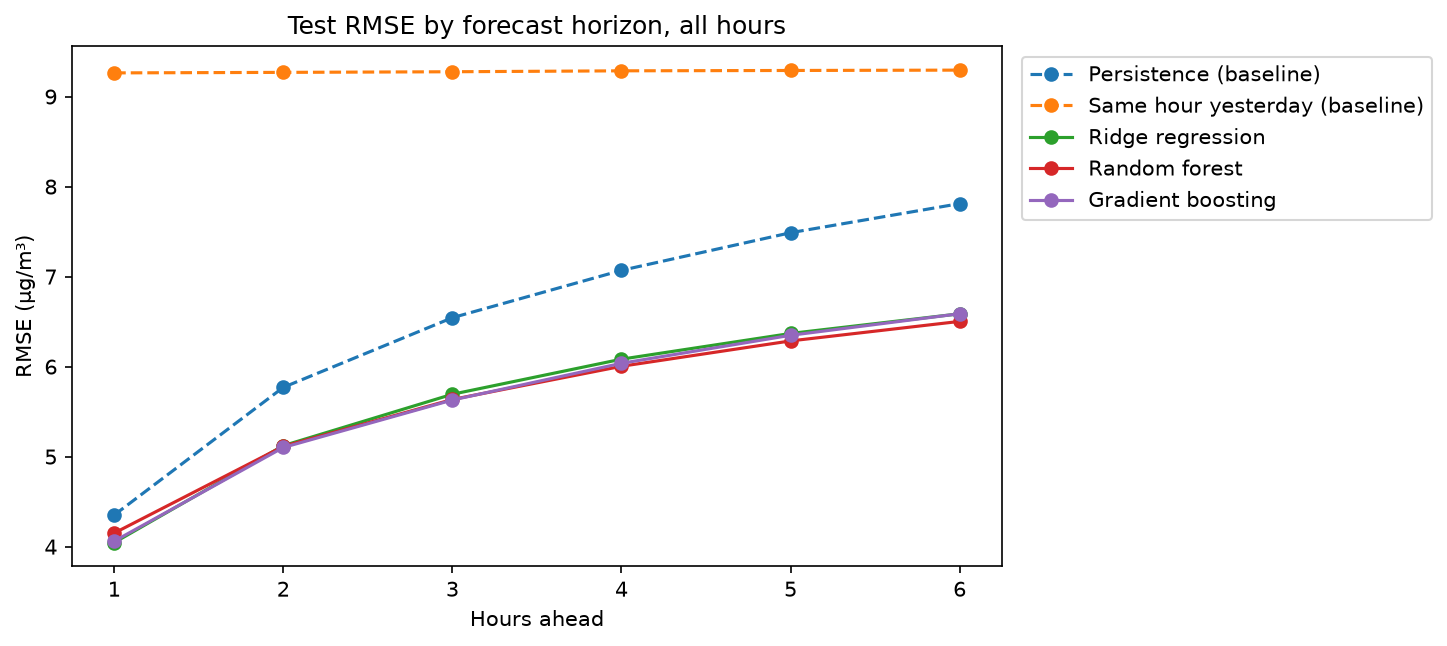

In [7]:
evaluate.main()  # recreates figures 07–13 and results/worst_errors.csv
display(Image(FIGURES / "07_test_rmse_by_horizon.png"))

**Observation:** on all hours, every learned model beats persistence at
every horizon. The gain grows with the horizon: ≈ 7 % lower RMSE at 1 h and
≈ 16 % at 6 h (overall mean RMSE 5.63 vs 6.51 µg/m³). The "same hour
yesterday" baseline is far worse: the daily cycle is weak, as notebook 01
showed.

## 4. Where it fails: haze hours

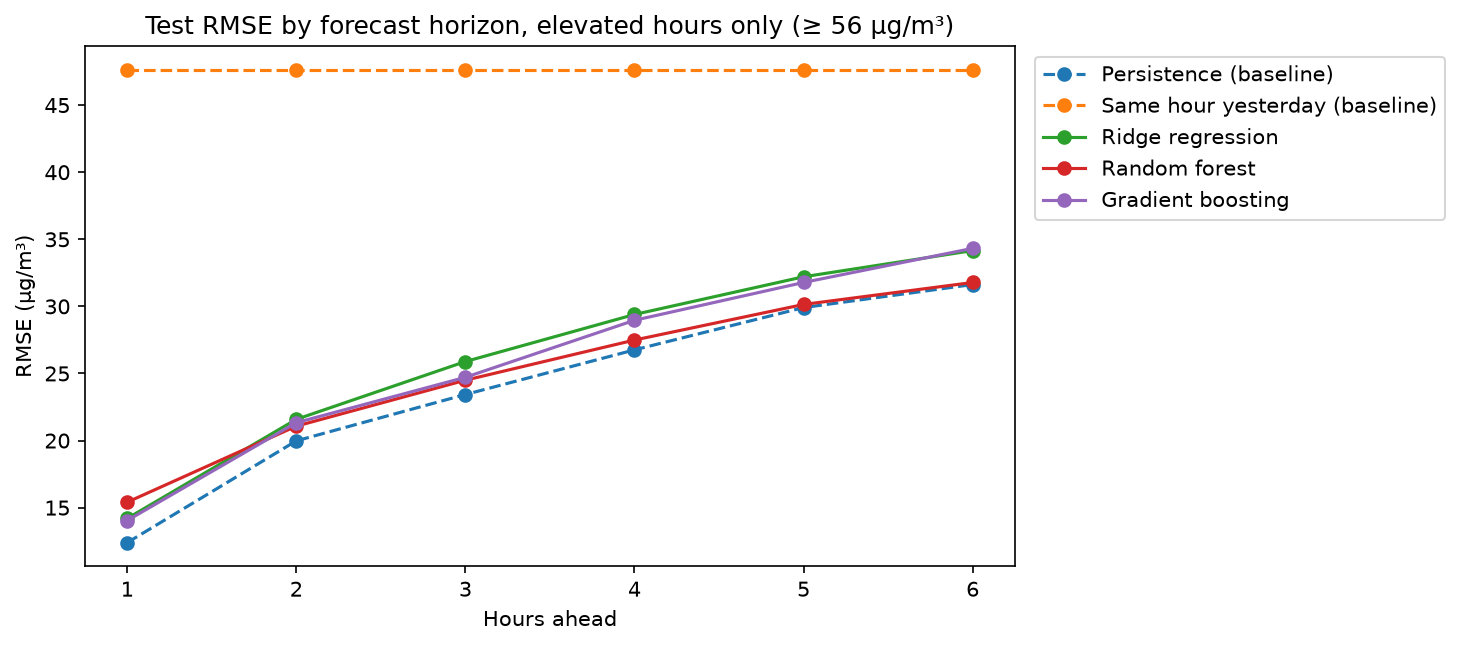

In [8]:
display(Image(FIGURES / "08_test_rmse_elevated_by_horizon.png"))

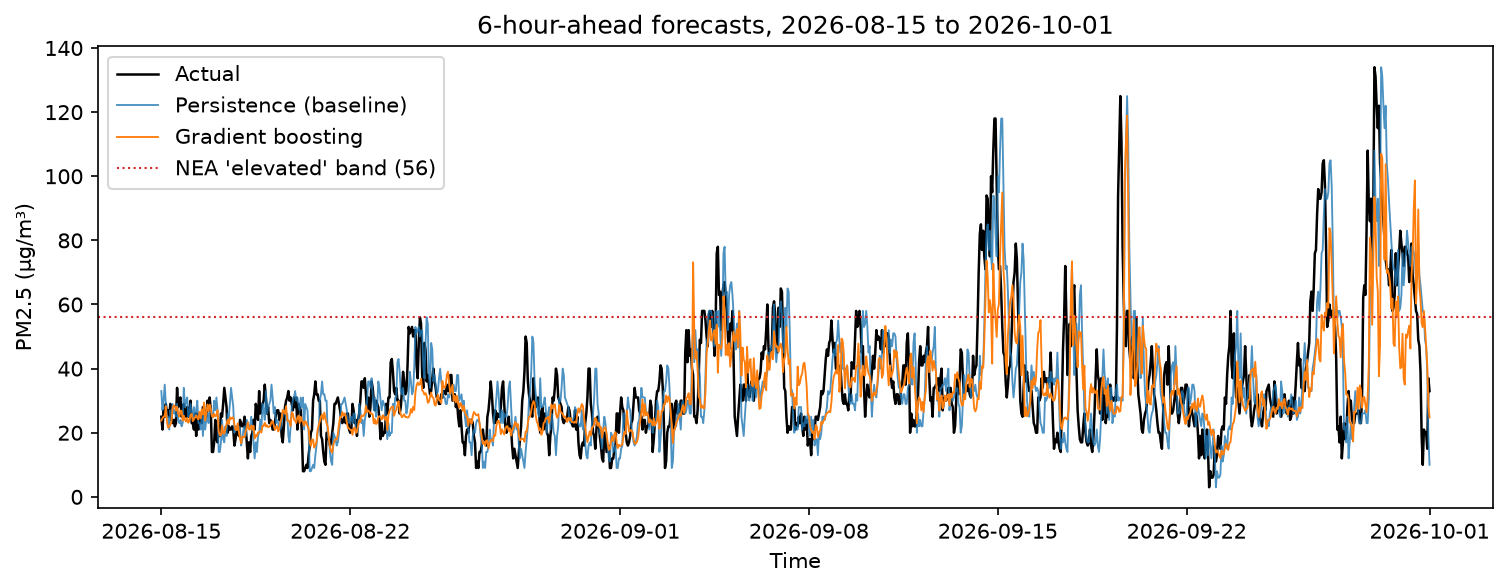

In [9]:
display(Image(FIGURES / "10_forecast_haze_2026_h6.png"))

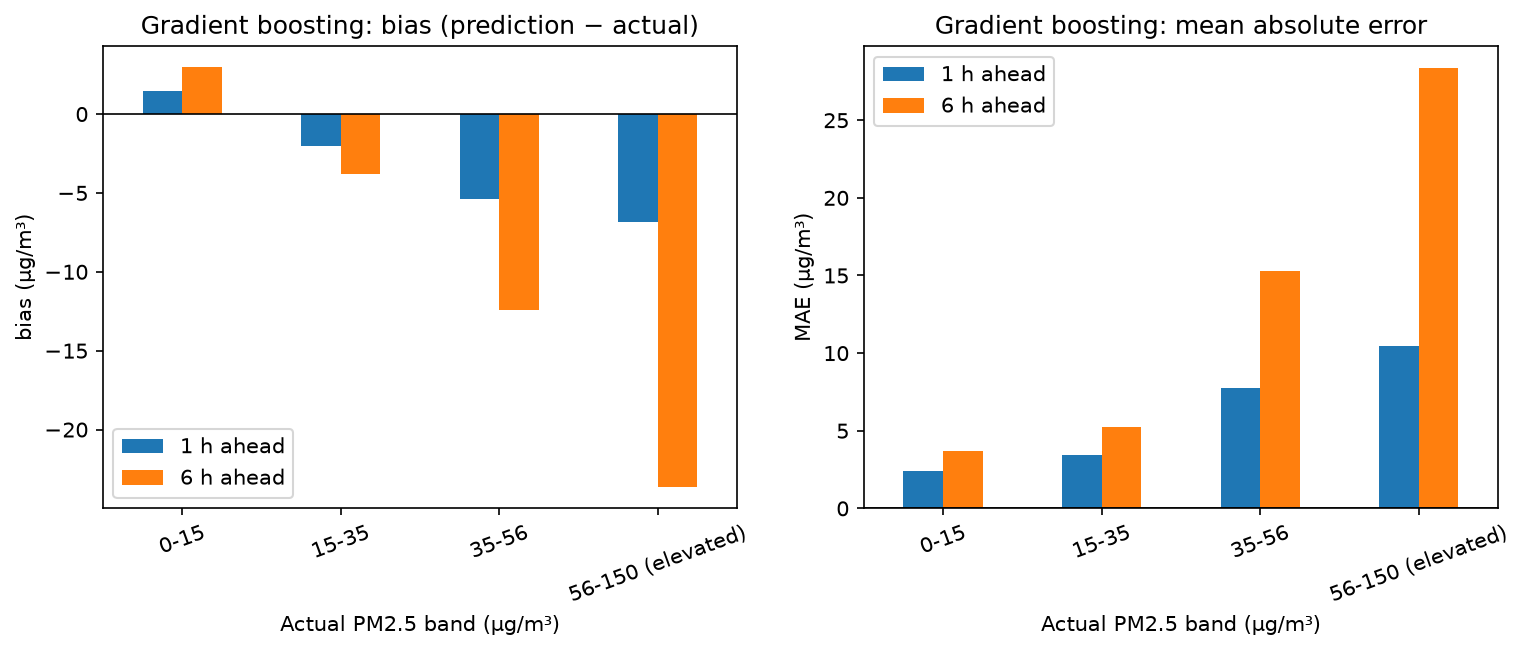

In [10]:
display(Image(FIGURES / "11_error_by_level.png"))

In [11]:
pd.read_csv(train.RESULTS_DIR / "worst_errors.csv")

,origin,target_time,actual,persistence,hist_gradient_boosting,error
0,2026-09-19 07:00:00,2026-09-19 13:00:00,125.0,30.0,26.7,-98.3
1,2026-09-28 21:00:00,2026-09-29 03:00:00,122.0,72.0,37.6,-84.4
2,2026-09-19 06:00:00,2026-09-19 12:00:00,109.0,31.0,26.5,-82.5
3,2026-09-19 08:00:00,2026-09-19 14:00:00,111.0,31.0,31.2,-79.8
4,2026-09-28 11:00:00,2026-09-28 17:00:00,108.0,23.0,31.2,-76.8
5,2026-09-19 05:00:00,2026-09-19 11:00:00,94.0,30.0,27.9,-66.1
6,2026-09-19 12:00:00,2026-09-19 18:00:00,47.0,109.0,110.8,63.8
7,2026-09-14 16:00:00,2026-09-14 22:00:00,118.0,82.0,55.7,-62.3
8,2026-09-19 13:00:00,2026-09-19 19:00:00,58.0,125.0,118.9,60.9
9,2026-09-14 15:00:00,2026-09-14 21:00:00,118.0,93.0,61.2,-56.8


**Observation – the model's main weakness.** On *elevated* hours
(≥ 56 µg/m³, NEA Band II; 144 such hours per horizon in the test period, almost
all in the September 2026 haze) the learned models are **slightly worse than persistence**
(mean RMSE ≈ 25.9 vs 24.0).

The bias chart shows why: the model is **pulled towards the typical value**.
It over-predicts a little on clean hours and increasingly under-predicts as
pollution rises (≈ −24 µg/m³ at 6 h ahead on elevated hours). Squared-error
training on data where 99 % of hours are below 56 µg/m³ rewards cautious forecasts.

The worst errors are sudden haze spikes (e.g. 19 Sep 2026, 13:00: actual 125,
forecast 27 six hours earlier). The inputs at forecast time showed nothing
unusual, so no model using only past PM2.5 could anticipate them; the onset is
driven by wind direction and regional fires, which are not in our data.

**Practical meaning:** for everyday planning the model is better than "assume
it stays the same", but it must not be the only warning system during haze.
See the README for recommendations.

## 5. What the model relies on

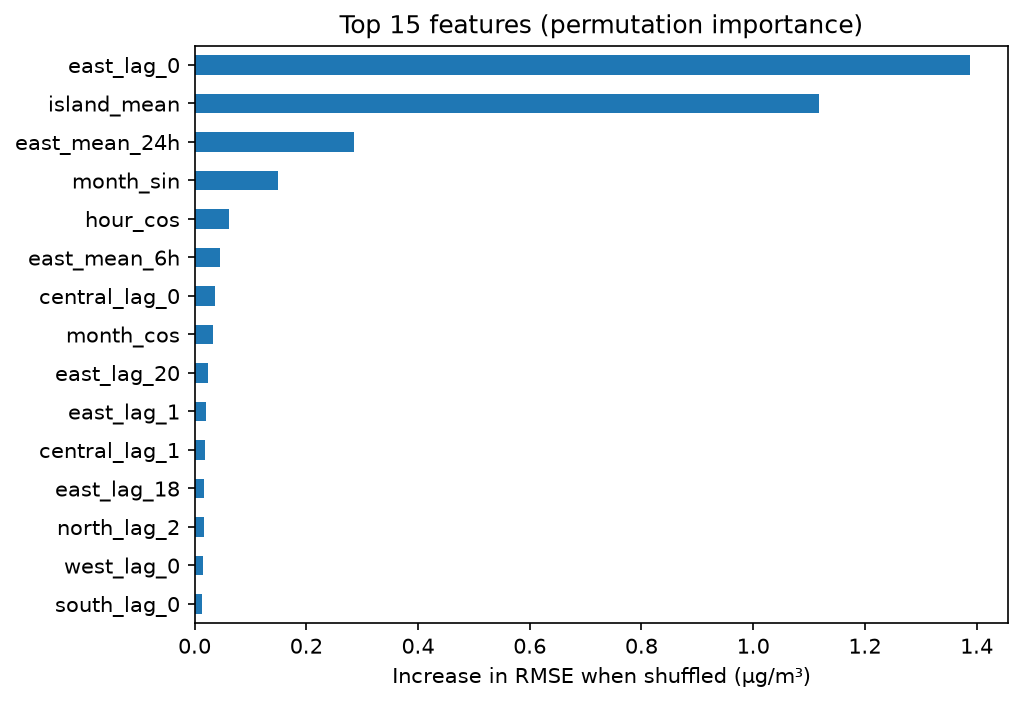

In [12]:
display(Image(FIGURES / "12_feature_importance.png"))

**Observation:** the latest East reading and the island-wide mean
dominate, followed by the 24-hour average and the month (haze season). Older
individual lags add little once the rolling averages are present. This
matches the autocorrelation analysis in notebook 01.

## 6. Bias audit across regions

RMSE_mean                 RMSE_elevated_mean            
model   hist_gradient_boosting persistence hist_gradient_boosting persistence
region                                                                       
central                   6.72        7.44                  32.30       25.43
east                      5.63        6.51                  25.86       24.02
north                     5.25        6.24                  24.37       21.77
south                     5.49        6.35                  27.18       25.86
west                      5.66        6.50                  24.75       23.29

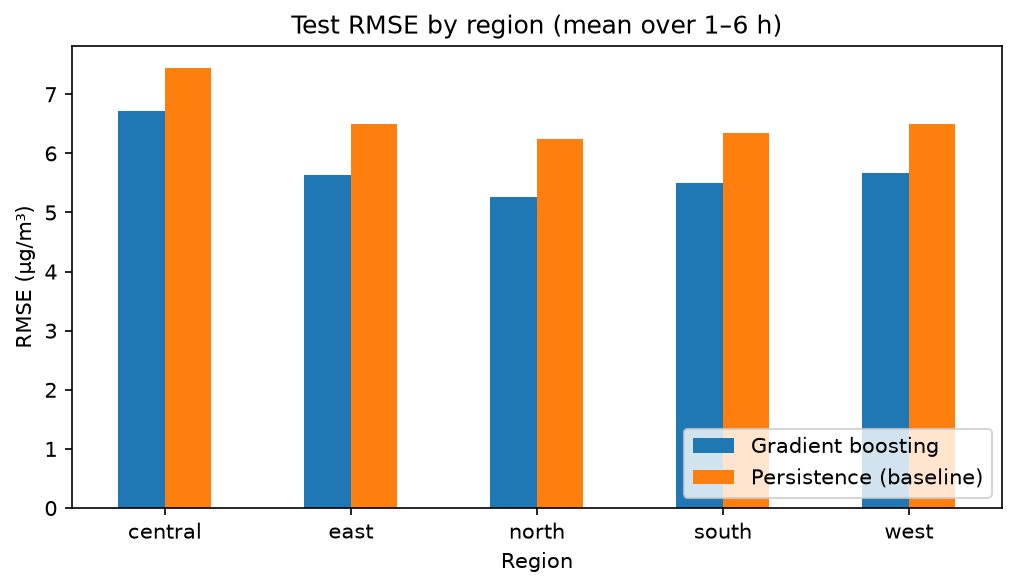

In [13]:
audit = pd.read_csv(train.RESULTS_DIR / "region_audit.csv")
display(audit.pivot(index="region", columns="model", values=["RMSE_mean", "RMSE_elevated_mean"]).round(2))
display(Image(FIGURES / "13_region_audit.png"))

**Observation:** retraining the same model for each region gives the same
picture everywhere: about 10–16 % lower RMSE than persistence overall, but higher
error on elevated hours. Central is the hardest region (highest RMSE, and the
largest gap on haze hours), so its forecasts deserve the most caution. No
region is left behind on ordinary days.

## 7. Using the model (batch demo)

In [14]:
import joblib

bundle = joblib.load(train.MODEL_PATH)
recent = load_clean().tail(48)   # stand-in for "the latest 48 hours of readings"
forecast(recent, bundle)

,forecast_for,hours_ahead,east_pm25,nea_band
0,2026-10-01 01:00:00,1,31.1,Normal
1,2026-10-01 02:00:00,2,32.6,Normal
2,2026-10-01 03:00:00,3,31.9,Normal
3,2026-10-01 04:00:00,4,32.7,Normal
4,2026-10-01 05:00:00,5,35.2,Normal
5,2026-10-01 06:00:00,6,36.9,Normal


The same thing from the command line: `python -m src.predict`
(or `--input my_readings.csv`). One forecast takes a few milliseconds.